In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Set random seed for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# 1. Generate 2-Feature Synthetic Dataset
X, y = make_classification(
    n_samples=1000,
    n_features=2,        # Only 2 features (e.g., Feature1, Feature2)
    n_informative=2,    # Both features carry useful signal
    n_redundant=0,
    n_clusters_per_class=1,
    n_classes=2,
    random_state=42
)

# 2. Train / Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Standardize Features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 4. Convert to TensorFlow Dataset objects
batch_size = 32
train_dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(1000).batch(batch_size)
test_dataset = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(batch_size)

# Verification
print(f"X_train shape: {X_train.shape}")  # Outputs: (800, 2)
print(f"y_train shape: {y_train.shape}")  # Outputs: (800,)

X_train shape: (800, 2)
y_train shape: (800,)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [ ]:
model = Sequential()

model.add(Dense(units = 2 , input_dim = 2, activation = 'sigmoid'))
model.add(Dense(units= 1 , activation = 'sigmoid'))

In [ ]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 2)              │             6 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9 (36.00 B)

 Trainable params: 9 (36.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.get_weights()

[array([[-0.3027032,  1.167761 ],
        [-1.1946545,  1.1291503]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[-0.7196817],
        [-1.0329612]], dtype=float32),
 array([0.], dtype=float32)]

In [ ]:
initial_weights = model.get_weights()
initial_weights[0] = np.zeros(model.get_weights()[0].shape)
initial_weights[1] = np.zeros(model.get_weights()[1].shape)
initial_weights[2] = np.zeros(model.get_weights()[2].shape)
initial_weights[3] = np.zeros(model.get_weights()[3].shape)

In [ ]:
model.set_weights(initial_weights)

In [ ]:
model.get_weights()

[array([[0., 0.],
        [0., 0.]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[0.],
        [0.]], dtype=float32),
 array([0.], dtype=float32)]

In [ ]:
model.compile(optimizer= 'adam'  , loss = 'binary_crossentropy' , metrics=['accuracy'])

In [ ]:
history = model.fit(x = X_train , y = y_train , epochs = 100 , validation_data = (X_test , y_test) )

Epoch 1/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.4588 - loss: 0.6933 - val_accuracy: 0.5200 - val_loss: 0.6931
Epoch 2/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.4963 - loss: 0.6932 - val_accuracy: 0.5200 - val_loss: 0.6931
Epoch 3/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.4487 - loss: 0.6932 - val_accuracy: 0.4800 - val_loss: 0.6931
Epoch 4/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.4663 - loss: 0.6932 - val_accuracy: 0.5600 - val_loss: 0.6931
Epoch 5/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.4650 - loss: 0.6931 - val_accuracy: 0.5200 - val_loss: 0.6930
Epoch 6/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.4963 - loss: 0.6930 - val_accuracy: 0.5200 - val_loss: 0.6927
Epoch 7/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.4963 - loss: 0.6927 - val_accuracy: 0.5200 - val_loss: 0.6922
Epoch 8/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.4963 - loss: 0.6922 - val_accuracy: 0.5

In [ ]:
model.get_weights()

[array([[-0.06628951, -0.06628951],
        [-2.9567401 , -2.9567401 ]], dtype=float32),
 array([-0.5754798, -0.5754798], dtype=float32),
 array([[-1.8013053],
        [-1.8013053]], dtype=float32),
 array([1.2823613], dtype=float32)]

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 15s 2ms/step


<Axes: >

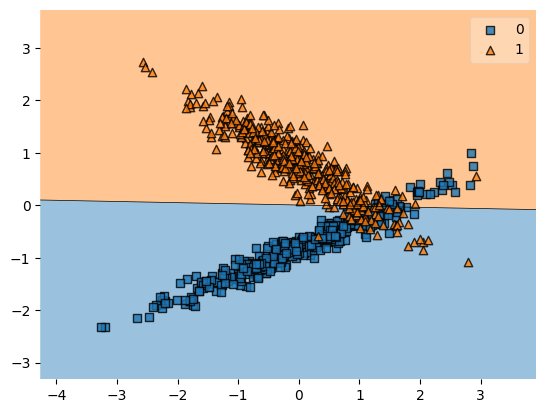

In [ ]:
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(X_train , y_train , clf = model)

### **Zero Weight Initialization Observation (Sigmoid Activation)**

* **Forward Pass:**
  For any input $x$, $z = Wx + b = 0 \implies \sigma(0) = \frac{1}{1 + e^{-0}} = 0.5$.
  Every neuron in the hidden layer outputs exactly $0.5$.

* **Gradients & Backpropagation:**
  The derivative of Sigmoid at $0$ is $\sigma'(0) = 0.5 \cdot (1 - 0.5) = 0.25$.
  Because all hidden neurons have identical outputs ($0.5$) and identical derivatives ($0.25$), every neuron in the same hidden layer receives the exact same gradient value ($\frac{\partial L}{\partial W}$).

* **Symmetry Problem:**
  All weights in a hidden layer update by the exact same amount during backpropagation ($w_i \leftarrow w_i - \eta \frac{\partial L}{\partial w}$).
  Symmetry is **never broken**—every neuron inside the hidden layer learns identical features, reducing the entire hidden layer's representation capacity down to a single neuron.

* **Summary Comparison across Activations (Zero Initialization):**
  * **Tanh:** Outputs $0$, gradients are non-zero but **identical** $\implies$ Symmetry unbroken.
  * **ReLU:** Outputs $0$, gradients are $0$ $\implies$ Weights do not update at all (dead model).
  * **Sigmoid:** Outputs $0.5$, gradients are non-zero but **identical** $\implies$ Symmetry unbroken.

* **Non-Zero Constant Initialization (e.g., $W = c$, where $c \neq 0$):**
  Setting all weights to the exact same non-zero constant (e.g., $W = 0.5$ or $W = 1.0$) causes the exact same **Symmetry Problem** as zero initialization.
  
  Even though outputs and gradients may be non-zero (avoiding dead ReLU nodes at step 0), every neuron in a hidden layer receives identical inputs, computes identical activations, and receives identical gradient updates. Because no individual neuron has a distinct weight vector, symmetry is never broken, and all neurons continue to update identically forever—reducing the layer to a single effective neuron regardless of activation function ($\text{Sigmoid}$, $\text{Tanh}$, or $\text{ReLU}$).